# DenseNet169_HD - Hair Disease Classification (10 classes)

**Run the cells strictly from top to bottom, one at a time, and read each output before moving on.**

Pipeline follows the public repo *Visual-Recognition-of-Hair-Disorders* (DenseNet169, ImageNet weights,
GlobalAveragePooling -> Dense(512, ReLU) -> Dropout -> Softmax, 224x224 input, pixels scaled to [0,1],
rotation / shift / zoom / flip augmentation). Folder layout, data split and evaluation code are the same as
`InceptionV3_HD.ipynb`, so the results are directly comparable.

Differences from the repo (on purpose, for a rigorous thesis): validation-loss early stopping, a second
fine-tuning phase (last dense block `conv5`), fixed seed, leakage check, test set used once, bootstrap CI.

| Part | Cells | What it produces |
|---|---|---|
| A. Setup | 1-5 | GPU check, Drive, config, seed + mixed precision, data copied to Colab disk |
| B. Data verification | 6-12 | Class counts, leakage check between splits, sample images |
| C. Model sanity checks | 13-16 | Proof that the model and pipeline work before real training |
| D. Training | 17-24 | Phase 1 (head only) and Phase 2 (fine-tune conv5), curves, best checkpoint |
| E. Final test evaluation | 25-32 | Metrics, confusion matrix, 95% CI, error analysis (**run once**) |
| F. Save | 33 | Summary of the whole experiment |

Every run writes to its own folder `results/<RUN_NAME>/`, so nothing is overwritten.
To report mean +- std, repeat the whole notebook with `SEED = 42, 123, 2024`.

## A. Setup

### Cell 1 - Imports, library versions, GPU
Expected: a GPU name (e.g. Tesla T4). If the list is empty: Runtime > Change runtime type > T4 GPU.

In [1]:
import os, sys, json, time, random, zipfile, subprocess, platform, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import sklearn
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
                             f1_score, cohen_kappa_score, roc_auc_score, classification_report,
                             confusion_matrix)
from PIL import Image

print("Python     :", platform.python_version())
print("TensorFlow :", tf.__version__)
print("Keras      :", tf.keras.__version__)
print("NumPy      :", np.__version__)
print("scikit-learn:", sklearn.__version__)

gpus = tf.config.list_physical_devices("GPU")
print("GPUs       :", gpus)
assert gpus, "No GPU found. Runtime > Change runtime type > T4 GPU, then restart."
print(subprocess.run(["nvidia-smi", "-L"], capture_output=True, text=True).stdout)

Python     : 3.13.16
TensorFlow : 2.21.0
Keras      : 3.13.2
NumPy      : 2.1.3
scikit-learn: 1.6.1
GPUs       : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
GPU 0: Tesla T4 (UUID: GPU-d4b0d0d9-0946-2e1f-0fed-ac843b041c25)



### Cell 2 - Mount Google Drive
A pop-up will ask for permission. Click Allow.

In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


### Cell 3 - Experiment configuration
**Edit `DRIVE_DIR` only** (the Drive folder that contains `data_processed/` and `results/`).
All hyper-parameters live here, so they are recorded with the results.
Items marked `(assumed)` are not stated in the repo README; change them only before the first real run.

In [3]:
# ------------------------------------------------------------- EDIT THIS LINE
DRIVE_DIR = "/content/drive/MyDrive/Hair-Disease-Research"
# -------------------------------------------------------------------------

SEED = 42
ZIP_PATH = f"{DRIVE_DIR}/data_processed/dataset_224_v3.zip"
RESULTS_ROOT = f"{DRIVE_DIR}/results"
DATA_DIR = "/content/dataset_224_v3"       # local copy on Colab disk (fast)

IMG_SIZE = (224, 224)         # stored size AND DenseNet169 input size (no resizing needed)
MODEL_NAME = "densenet169"
BATCH = 32
MIXED_PRECISION = True        # float16 compute on T4; output layer stays float32

# Input scaling: "repo_01" = pixels/255 (as in the repo); "imagenet_torch" = /255 then ImageNet mean/std
PREPROCESS = "repo_01"

# Head (repo): GlobalAveragePooling -> Dense(512, relu) -> Dropout -> Dense(10, softmax)
DENSE_UNITS = 512
DROPOUT = 0.5                 # (assumed) repo README does not give the value

# Phase 1: train the new classification head, backbone frozen
EPOCHS_P1 = 10
LR_P1 = 1e-3
ES_PATIENCE_P1 = 4

# Phase 2: fine-tune the last dense block (conv5_*) of DenseNet169; BatchNorm layers stay frozen
EPOCHS_P2 = 25
LR_P2 = 1e-5
FINE_TUNE_FROM_LAYER = "conv5_block1_0_bn"   # first layer of the last dense block
ES_PATIENCE_P2 = 6

# Augmentation (repo: rotation, width/height shift, zoom, flip)
AUG = {"flip": "horizontal", "rotation": 0.05, "shift": 0.1, "zoom": 0.1}

RUN_NAME = f"{MODEL_NAME}_seed{SEED}_" + datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
RUN_DIR = f"{RESULTS_ROOT}/{RUN_NAME}"

assert os.path.exists(ZIP_PATH), f"Zip not found: {ZIP_PATH}\nCheck DRIVE_DIR and the folder structure."
os.makedirs(RUN_DIR, exist_ok=True)

CONFIG = {k: v for k, v in globals().items()
          if k.isupper() and isinstance(v, (int, float, str, tuple, dict))}
json.dump(CONFIG, open(f"{RUN_DIR}/config.json", "w"), indent=2, default=str)
print("Run folder:", RUN_DIR)
print(json.dumps(CONFIG, indent=2, default=str))

Run folder: /content/drive/MyDrive/Hair-Disease-Research/results/densenet169_seed42_20261023_165946
{
  "DRIVE_DIR": "/content/drive/MyDrive/Hair-Disease-Research",
  "SEED": 42,
  "ZIP_PATH": "/content/drive/MyDrive/Hair-Disease-Research/data_processed/dataset_224_v3.zip",
  "RESULTS_ROOT": "/content/drive/MyDrive/Hair-Disease-Research/results",
  "DATA_DIR": "/content/dataset_224_v3",
  "IMG_SIZE": [
    224,
    224
  ],
  "MODEL_NAME": "densenet169",
  "BATCH": 32,
  "MIXED_PRECISION": true,
  "PREPROCESS": "repo_01",
  "DENSE_UNITS": 512,
  "DROPOUT": 0.5,
  "EPOCHS_P1": 10,
  "LR_P1": 0.001,
  "ES_PATIENCE_P1": 4,
  "EPOCHS_P2": 25,
  "LR_P2": 1e-05,
  "FINE_TUNE_FROM_LAYER": "conv5_block1_0_bn",
  "ES_PATIENCE_P2": 6,
  "AUG": {
    "flip": "horizontal",
    "rotation": 0.05,
    "shift": 0.1,
    "zoom": 0.1
  },
  "RUN_NAME": "densenet169_seed42_20261023_165946",
  "RUN_DIR": "/content/drive/MyDrive/Hair-Disease-Research/results/densenet169_seed42_20261023_165946"
}


### Cell 4 - Fix random seeds and set mixed precision
Seeds make the run repeatable as far as possible. GPU kernels are not perfectly deterministic,
so tiny differences between runs with the same seed are normal. Mention this in the report.
Mixed precision (float16) speeds up training on the T4; the final softmax layer is kept in float32.
Report it in the methods section.

In [4]:
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
if MIXED_PRECISION:
    tf.keras.mixed_precision.set_global_policy("mixed_float16")
print("Seed set to", SEED, "| dtype policy:", tf.keras.mixed_precision.global_policy().name)

Seed set to 42 | dtype policy: mixed_float16


### Cell 5 - Copy and unzip the dataset to the Colab disk
Expected: `['train', 'val', 'test']`. Takes 1-3 minutes the first time.

In [5]:
if not os.path.exists(DATA_DIR):
    t0 = time.time()
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall("/content")
    print(f"Unzipped in {time.time() - t0:.0f}s")
print(sorted(d for d in os.listdir(DATA_DIR) if not d.startswith(".")))

Unzipped in 6s
['test', 'train', 'val']


## B. Data verification

### Cell 6 - Class names and image counts per split
Expected: 10 classes, identical in all three splits; about 70/15/15 split
(train 8328, val 1785, test 1783, total 11896).

In [6]:
SPLITS = ["train", "val", "test"]

def list_classes(split):
    p = f"{DATA_DIR}/{split}"
    return sorted(d for d in os.listdir(p) if os.path.isdir(f"{p}/{d}") and not d.startswith("."))

cls_by_split = {s: list_classes(s) for s in SPLITS}
assert cls_by_split["train"] == cls_by_split["val"] == cls_by_split["test"], "Class folders differ between splits!"

def n_images(split, c):
    return len([f for f in os.listdir(f"{DATA_DIR}/{split}/{c}") if f.lower().endswith((".jpg", ".jpeg", ".png"))])

counts = pd.DataFrame({s: {c: n_images(s, c) for c in cls_by_split[s]} for s in SPLITS})
counts.loc["TOTAL"] = counts.sum()
counts["all"] = counts[SPLITS].sum(axis=1)
print(counts)
counts.to_csv(f"{RUN_DIR}/class_counts.csv")

                       train   val  test    all
Alopecia Areata          835   179   179   1193
Contact Dermatitis       834   179   179   1192
Folliculitis             834   179   178   1191
Head Lice                836   179   179   1194
Lichen Planus            836   179   179   1194
Male Pattern Baldness    776   166   166   1108
Psoriasis                787   169   169   1125
Seborrheic Dermatitis    807   173   173   1153
Telogen Effluvium        801   172   171   1144
Tinea Capitis            839   180   180   1199
TOTAL                   8185  1755  1753  11693


### Cell 7 - Class distribution plot
Check that no class is far smaller than the others.

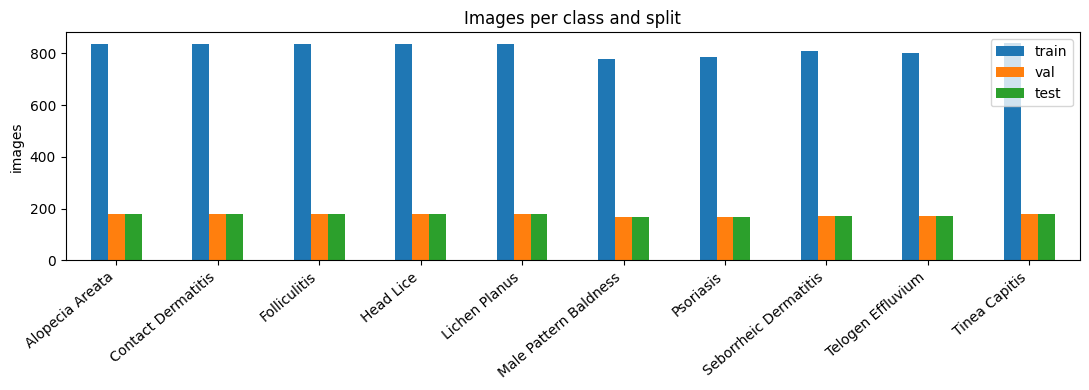

                       train    val   test
Alopecia Areata        0.102  0.102  0.102
Contact Dermatitis     0.102  0.102  0.102
Folliculitis           0.102  0.102  0.102
Head Lice              0.102  0.102  0.102
Lichen Planus          0.102  0.102  0.102
Male Pattern Baldness  0.095  0.095  0.095
Psoriasis              0.096  0.096  0.096
Seborrheic Dermatitis  0.099  0.099  0.099
Telogen Effluvium      0.098  0.098  0.098
Tinea Capitis          0.103  0.103  0.103


In [7]:
c2 = counts.drop(index="TOTAL")[SPLITS]
ax = c2.plot(kind="bar", figsize=(11, 4))
ax.set_ylabel("images"); ax.set_title("Images per class and split")
plt.xticks(rotation=40, ha="right"); plt.tight_layout()
plt.savefig(f"{RUN_DIR}/class_distribution.png", dpi=150); plt.show()
print((c2 / c2.sum()).round(3))

### Cell 8 - Load the three datasets
Expected output: `Found N files belonging to 10 classes` for each split.

In [8]:
def load_split(split, shuffle):
    return tf.keras.utils.image_dataset_from_directory(
        f"{DATA_DIR}/{split}", image_size=IMG_SIZE, batch_size=BATCH,
        label_mode="int", shuffle=shuffle, seed=SEED)

train_raw = load_split("train", True)
val_raw = load_split("val", False)
test_raw = load_split("test", False)

class_names = train_raw.class_names
NUM_CLASSES = len(class_names)
assert class_names == val_raw.class_names == test_raw.class_names
print("Classes:", class_names)

# file lists (val/test are not shuffled, so file order == prediction order)
train_files, val_files, test_files = train_raw.file_paths, val_raw.file_paths, test_raw.file_paths
print(len(train_files), len(val_files), len(test_files))

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_raw.prefetch(AUTOTUNE)
val_ds = val_raw.prefetch(AUTOTUNE)
test_ds = test_raw.prefetch(AUTOTUNE)
json.dump(class_names, open(f"{RUN_DIR}/class_names.json", "w"))

Found 8185 files belonging to 10 classes.
Found 1755 files belonging to 10 classes.
Found 1753 files belonging to 10 classes.
Classes: ['Alopecia Areata', 'Contact Dermatitis', 'Folliculitis', 'Head Lice', 'Lichen Planus', 'Male Pattern Baldness', 'Psoriasis', 'Seborrheic Dermatitis', 'Telogen Effluvium', 'Tinea Capitis']
8185 1755 1753


### Cell 9 - Leakage check (1/3): install and compute perceptual hashes
(Two code cells below: first the install, then the hashing. Run both.)
This is an **independent re-check after the re-split**. Hashes are computed on the final 224x224 images.

In [9]:
%pip install -q imagehash

In [10]:
import imagehash
from PIL import ImageOps

def phash_int(im):
    bits = imagehash.phash(im).hash.flatten()
    return np.uint64(int("".join("1" if b else "0" for b in bits), 2))

def hashes(files, flip=False):
    out = np.zeros(len(files), dtype=np.uint64)
    for i, f in enumerate(files):
        with Image.open(f) as im:
            im = im.convert("RGB")
            out[i] = phash_int(ImageOps.mirror(im) if flip else im)
    return out

t0 = time.time()
H = {"train": hashes(train_files), "val": hashes(val_files), "test": hashes(test_files)}
H_flip = {"val": hashes(val_files, flip=True), "test": hashes(test_files, flip=True)}
print(f"Hashing done in {time.time() - t0:.0f}s")

Hashing done in 38s


### Cell 10 - Leakage check (2/3): compare splits
Counts image pairs from different splits whose pHash distance is small (<=2 = nearly identical, <=4 = very similar).
The `flipped` rows compare mirrored val/test images with train, to catch horizontally flipped copies.

**Interpretation:** ideally 0 or very few. Because the hash is now computed on padded images, numbers differ
from the earlier audit. A handful of pairs at distance 3-4 can be visually similar but different patients/photos;
look at a few before deciding anything.

In [11]:
POP = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)

def cross_pairs(a, b, thr):
    pairs = []
    for s in range(0, len(a), 256):
        x = a[s:s + 256, None] ^ b[None, :]
        d = POP[x.view(np.uint8).reshape(x.shape + (8,))].sum(axis=-1)
        for i, j in np.argwhere(d <= thr):
            pairs.append((s + int(i), int(j), int(d[i, j])))
    return pairs

rows, found = [], {}
for name, a, b in [("train vs val", H["train"], H["val"]),
                   ("train vs test", H["train"], H["test"]),
                   ("val vs test", H["val"], H["test"]),
                   ("train vs val (flipped)", H["train"], H_flip["val"]),
                   ("train vs test (flipped)", H["train"], H_flip["test"])]:
    p = cross_pairs(a, b, 4)
    found[name] = p
    rows.append({"comparison": name,
                 "pairs dist<=2": sum(1 for _, _, d in p if d <= 2),
                 "pairs dist<=4": len(p)})
leak_df = pd.DataFrame(rows)
print(leak_df.to_string(index=False))
leak_df.to_csv(f"{RUN_DIR}/leakage_check.csv", index=False)

             comparison  pairs dist<=2  pairs dist<=4
           train vs val              0              0
          train vs test              0              0
            val vs test              0              0
 train vs val (flipped)              0              0
train vs test (flipped)              0              0


### Cell 11 - Leakage check (3/3): look at the closest pairs between train and test
If pairs exist, this shows the 6 closest ones. Same lesion/photo in both => leakage.

In [12]:
p = sorted(found["train vs test"], key=lambda t: t[2])[:6]
if not p:
    print("No train/test pair with pHash distance <= 4.")
else:
    fig, ax = plt.subplots(len(p), 2, figsize=(5, 2.6 * len(p)))
    ax = np.atleast_2d(ax)
    for r, (i, j, d) in enumerate(p):
        for c, f in enumerate([train_files[i], test_files[j]]):
            ax[r, c].imshow(Image.open(f)); ax[r, c].axis("off")
            ax[r, c].set_title(("train" if c == 0 else "test") + f" | d={d}\n" + os.path.basename(f), fontsize=7)
    plt.tight_layout(); plt.savefig(f"{RUN_DIR}/closest_train_test_pairs.png", dpi=130); plt.show()

No train/test pair with pHash distance <= 4.


### Cell 12 - Look at some training images
Check that images look correct and that labels match the pictures.

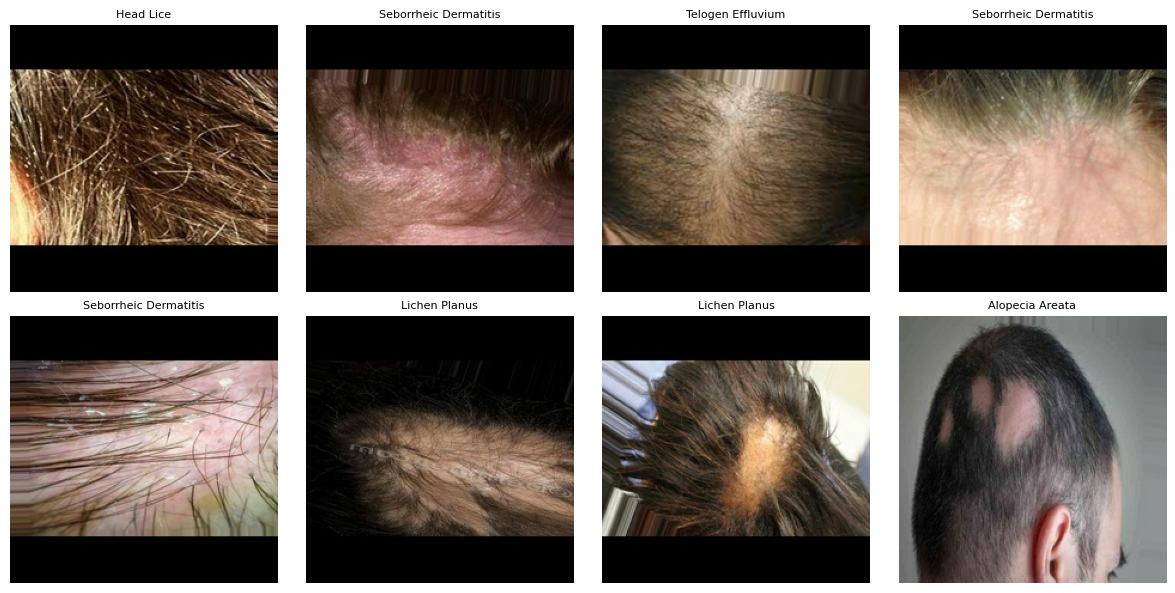

In [13]:
plt.figure(figsize=(12, 6))
for images, labels in train_raw.take(1):
    for i in range(8):
        plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]], fontsize=8); plt.axis("off")
plt.tight_layout(); plt.savefig(f"{RUN_DIR}/sample_train_images.png", dpi=130); plt.show()

## C. Model definition and sanity checks

### Cell 13 - Augmentation layers (training only) and a visual check
Augmentation is part of the model, and Keras switches it **off** automatically for validation and test.
Same family as the repo (rotation, shift, zoom, flip). Left: original. Others: random augmentations of the same image.

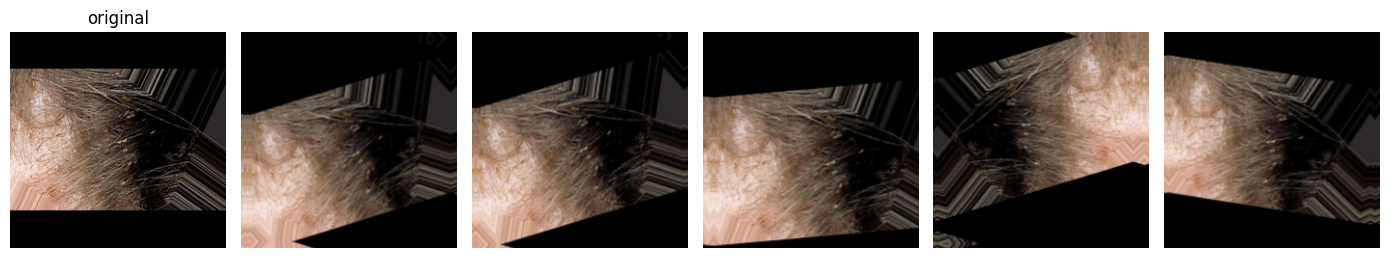

In [14]:
augment = tf.keras.Sequential([
    tf.keras.layers.RandomFlip(AUG["flip"]),
    tf.keras.layers.RandomRotation(AUG["rotation"]),
    tf.keras.layers.RandomTranslation(AUG["shift"], AUG["shift"]),
    tf.keras.layers.RandomZoom(AUG["zoom"]),
], name="augmentation")

img = next(iter(train_raw.take(1)))[0][:1]
plt.figure(figsize=(14, 3))
plt.subplot(1, 6, 1); plt.imshow(img[0].numpy().astype("uint8")); plt.title("original"); plt.axis("off")
for k in range(5):
    plt.subplot(1, 6, k + 2)
    plt.imshow(np.clip(augment(img, training=True)[0].numpy(), 0, 255).astype("uint8")); plt.axis("off")
plt.tight_layout(); plt.savefig(f"{RUN_DIR}/augmentation_check.png", dpi=130); plt.show()

### Cell 14 - Model builder
DenseNet169 (ImageNet weights) + GlobalAveragePooling + Dense(512, ReLU) + Dropout + softmax layer (as in the repo).
Images are stored at 224x224, which is the native size of DenseNet169, so there is no resizing step.
`Rescaling(1/255)` reproduces the repo's [0,1] scaling (set `PREPROCESS = "imagenet_torch"` for ImageNet mean/std).
The last layer uses `dtype="float32"` so the softmax is numerically safe under mixed precision.

In [15]:
def build_model():
    base = tf.keras.applications.DenseNet169(input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet")
    base.trainable = False
    inputs = tf.keras.Input(shape=IMG_SIZE + (3,))
    x = augment(inputs)
    x = tf.keras.layers.Rescaling(1 / 255.0)(x)                 # repo: pixels scaled to [0,1]
    if PREPROCESS == "imagenet_torch":
        x = tf.keras.layers.Normalization(mean=[0.485, 0.456, 0.406],
                                          variance=[0.229 ** 2, 0.224 ** 2, 0.225 ** 2])(x)
    x = base(x, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(DENSE_UNITS, activation="relu")(x)
    x = tf.keras.layers.Dropout(DROPOUT)(x)
    outputs = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax", dtype="float32")(x)
    return tf.keras.Model(inputs, outputs), base

def compile_model(m, lr):
    m.compile(optimizer=tf.keras.optimizers.Adam(lr),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
print("builder ready")

builder ready


### Cell 15 - Sanity check 1: initial loss
A randomly initialised 10-class head should give loss close to ln(10) = 2.30 and accuracy near 10%.
Much higher or lower values mean something is wrong (labels, preprocessing, loss function).

In [16]:
xv, yv = next(iter(val_raw.take(1)))
m0, _ = build_model(); compile_model(m0, LR_P1)
loss0, acc0 = m0.evaluate(xv, yv, verbose=0)
print(f"initial loss = {loss0:.3f}   (expected about {np.log(NUM_CLASSES):.3f})")
print(f"initial acc  = {acc0:.3f}   (expected about {1 / NUM_CLASSES:.3f})")
del m0

51877672/51877672 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
initial loss = 3.528   (expected about 2.303)
initial acc  = 0.000   (expected about 0.100)


### Cell 16 - Sanity check 2: can the model overfit one small batch?
Train a throw-away model on a single batch of 32 images. Training accuracy should rise far above chance
(typically > 0.9). If it cannot, the pipeline has a bug. This model is discarded.

In [17]:
xb, yb = next(iter(train_raw.take(1)))
m1, _ = build_model(); compile_model(m1, LR_P1)
h = m1.fit(xb, yb, epochs=40, verbose=0)
print(f"loss  {h.history['loss'][0]:.3f} -> {h.history['loss'][-1]:.3f}")
print(f"acc   {h.history['accuracy'][0]:.3f} -> {h.history['accuracy'][-1]:.3f}")
del m1
tf.keras.backend.clear_session()

loss  2.861 -> 0.037
acc   0.156 -> 1.000


## D. Training

### Cell 17 - Build the real model
Expected: about 13.5M total parameters, of which about 857,610 are trainable (the new head:
1664 x 512 + 512 + 512 x 10 + 10).

In [18]:
tf.keras.utils.set_random_seed(SEED)
model, base = build_model()
compile_model(model, LR_P1)
model.summary(show_trainable=True)
n_train = int(sum(np.prod(w.shape) for w in model.trainable_weights))
n_total = int(model.count_params())
print(f"Trainable params: {n_train:,} / {n_total:,}")

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ input_layer_1 (InputLayer)  │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ augmentation (Sequential)   │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ rescaling (Rescaling)       │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ densenet169 (Functional)    │ (None, 7, 7, 1664)    │ 12,642,880 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ global_average_pooling2d    │ (None, 1664)          │          0 │   -   │
│ (GlobalAveragePooling2D)    │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dense (Dense)               │ (None, 512)           │    852,480 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout (Dropout)           │ (None, 512)           │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dense_1 (Dense)             │ (None, 10)            │      5,130 │   Y   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 13,500,490 (51.50 MB)

 Trainable params: 857,610 (3.27 MB)

 Non-trainable params: 12,642,880 (48.23 MB)

Trainable params: 857,610 / 13,500,490


### Cell 18 - Callbacks
Early stopping and checkpoints monitor **validation loss** (never the test set).

In [19]:
CKPT_P1 = f"{RUN_DIR}/ckpt_phase1.keras"
CKPT_P2 = f"{RUN_DIR}/ckpt_phase2.keras"

def make_callbacks(ckpt, patience, log_name):
    return [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-7, verbose=1),
        tf.keras.callbacks.ModelCheckpoint(ckpt, monitor="val_loss", save_best_only=True, verbose=0),
        tf.keras.callbacks.CSVLogger(f"{RUN_DIR}/{log_name}.csv"),
    ]
print("ok")

ok


### Cell 19 - Phase 1: train the classification head (backbone frozen)
Watch `val_loss`: it should decrease in the first epochs.

In [20]:
t0 = time.time()
h1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_P1,
               callbacks=make_callbacks(CKPT_P1, ES_PATIENCE_P1, "log_phase1"))
print(f"Phase 1 finished in {(time.time() - t0) / 60:.1f} min")

Epoch 1/10
256/256 ━━━━━━━━━━━━━━━━━━━━ 92s 276ms/step - accuracy: 0.7030 - loss: 0.9029 - val_accuracy: 0.7983 - val_loss: 0.5940 - learning_rate: 0.0010
Epoch 2/10
256/256 ━━━━━━━━━━━━━━━━━━━━ 63s 245ms/step - accuracy: 0.8955 - loss: 0.3377 - val_accuracy: 0.8843 - val_loss: 0.3490 - learning_rate: 0.0010
Epoch 3/10
256/256 ━━━━━━━━━━━━━━━━━━━━ 63s 245ms/step - accuracy: 0.9261 - loss: 0.2312 - val_accuracy: 0.9168 - val_loss: 0.2282 - learning_rate: 0.0010
Epoch 4/10
256/256 ━━━━━━━━━━━━━━━━━━━━ 63s 245ms/step - accuracy: 0.9516 - loss: 0.1611 - val_accuracy: 0.9276 - val_loss: 0.2041 - learning_rate: 0.0010
Epoch 5/10
256/256 ━━━━━━━━━━━━━━━━━━━━ 63s 244ms/step - accuracy: 0.9554 - loss: 0.1340 - val_accuracy: 0.9362 - val_loss: 0.1893 - learning_rate: 0.0010
Epoch 6/10
256/256 ━━━━━━━━━━━━━━━━━━━━ 60s 235ms/step - accuracy: 0.9618 - loss: 0.1206 - val_accuracy: 0.9299 - val_loss: 0.2183 - learning_rate: 0.0010
Epoch 7/10
256/256 ━━━━━━━━━━━━━━━━━━━━ 63s 244ms/step - accuracy: 0.9

### Cell 20 - Phase 1 result

In [21]:
d1 = pd.DataFrame(h1.history)
best1 = d1["val_loss"].idxmin()
print(f"Best epoch (phase 1): {best1 + 1}  val_loss={d1.loc[best1, 'val_loss']:.4f}  val_acc={d1.loc[best1, 'val_accuracy']:.4f}")
print(d1.round(4).to_string())

Best epoch (phase 1): 10  val_loss=0.0992  val_acc=0.9698
   accuracy    loss  val_accuracy  val_loss  learning_rate
0    0.7030  0.9029        0.7983    0.5940          0.001
1    0.8955  0.3377        0.8843    0.3490          0.001
2    0.9261  0.2312        0.9168    0.2282          0.001
3    0.9516  0.1611        0.9276    0.2041          0.001
4    0.9554  0.1340        0.9362    0.1893          0.001
5    0.9618  0.1206        0.9299    0.2183          0.001
6    0.9703  0.0981        0.9459    0.1654          0.001
7    0.9709  0.0941        0.9510    0.1384          0.001
8    0.9673  0.0937        0.9567    0.1170          0.001
9    0.9747  0.0777        0.9698    0.0992          0.001


### Cell 21 - Phase 2 setup: unfreeze the last dense block (conv5) of DenseNet169
All layers from `FINE_TUNE_FROM_LAYER` (`conv5_block1_0_bn`) onward are trained; everything before stays frozen.
BatchNorm layers always stay frozen (standard practice for small datasets).
Learning rate drops to `LR_P2`. The model is recompiled (required after changing `trainable`).

In [22]:
FINE_TUNE_AT = next(i for i, l in enumerate(base.layers) if l.name == FINE_TUNE_FROM_LAYER)
print(f"Unfreezing from layer index {FINE_TUNE_AT} ({FINE_TUNE_FROM_LAYER}) of {len(base.layers)} backbone layers")

base.trainable = True
for layer in base.layers[:FINE_TUNE_AT]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

compile_model(model, LR_P2)
n_train2 = int(sum(np.prod(w.shape) for w in model.trainable_weights))
print(f"Trainable params now: {n_train2:,} / {n_total:,}")

Unfreezing from layer index 369 (conv5_block1_0_bn) of 595 backbone layers
Trainable params now: 6,690,314 / 13,500,490


### Cell 22 - Phase 2: fine-tuning
This phase starts from the best phase-1 weights (restored by early stopping).

In [23]:
t0 = time.time()
h2 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_P2,
               callbacks=make_callbacks(CKPT_P2, ES_PATIENCE_P2, "log_phase2"))
print(f"Phase 2 finished in {(time.time() - t0) / 60:.1f} min")

Epoch 1/25
256/256 ━━━━━━━━━━━━━━━━━━━━ 110s 321ms/step - accuracy: 0.9849 - loss: 0.0458 - val_accuracy: 0.9681 - val_loss: 0.0979 - learning_rate: 1.0000e-05
Epoch 2/25
256/256 ━━━━━━━━━━━━━━━━━━━━ 73s 286ms/step - accuracy: 0.9918 - loss: 0.0244 - val_accuracy: 0.9778 - val_loss: 0.0630 - learning_rate: 1.0000e-05
Epoch 3/25
256/256 ━━━━━━━━━━━━━━━━━━━━ 70s 274ms/step - accuracy: 0.9944 - loss: 0.0197 - val_accuracy: 0.9738 - val_loss: 0.0732 - learning_rate: 1.0000e-05
Epoch 4/25
256/256 ━━━━━━━━━━━━━━━━━━━━ 0s 234ms/step - accuracy: 0.9955 - loss: 0.0176
Epoch 4: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
256/256 ━━━━━━━━━━━━━━━━━━━━ 70s 274ms/step - accuracy: 0.9956 - loss: 0.0158 - val_accuracy: 0.9749 - val_loss: 0.0649 - learning_rate: 1.0000e-05
Epoch 5/25
256/256 ━━━━━━━━━━━━━━━━━━━━ 73s 284ms/step - accuracy: 0.9955 - loss: 0.0152 - val_accuracy: 0.9812 - val_loss: 0.0493 - learning_rate: 5.0000e-06
Epoch 6/25
256/256 ━━━━━━━━━━━━━━━━━━━━ 70s 274ms/s

### Cell 23 - Training curves (both phases)
Look for overfitting: train accuracy far above val accuracy and val loss rising.

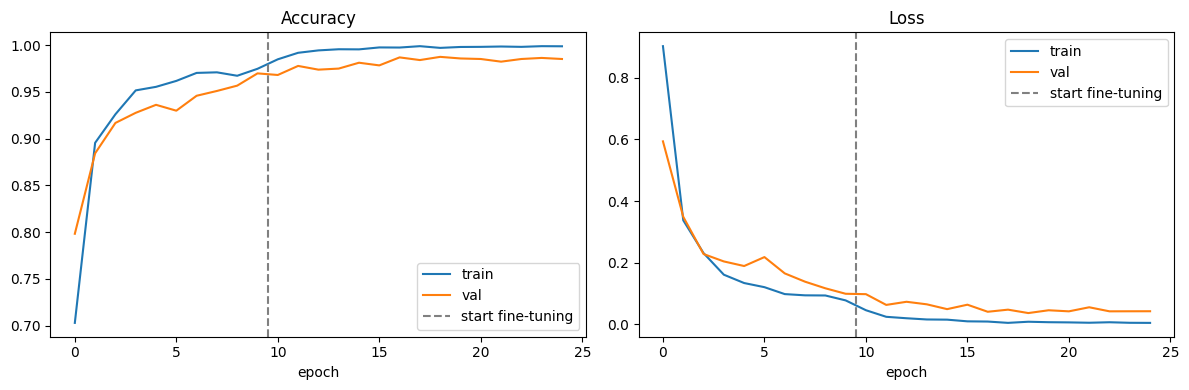

In [24]:
d2 = pd.DataFrame(h2.history)
hist = pd.concat([d1.assign(phase=1), d2.assign(phase=2)], ignore_index=True)
hist.to_csv(f"{RUN_DIR}/history_all.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, k, t in zip(ax, ["accuracy", "loss"], ["Accuracy", "Loss"]):
    a.plot(hist[k], label="train"); a.plot(hist["val_" + k], label="val")
    a.axvline(len(d1) - 0.5, color="gray", linestyle="--", label="start fine-tuning")
    a.set_title(t); a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.savefig(f"{RUN_DIR}/training_curves.png", dpi=150); plt.show()

### Cell 24 - Choose the final model using VALIDATION loss only
Fine-tuning does not always help. We evaluate both checkpoints on the validation set and keep the better one.

In [25]:
res = {}
for name, path in [("phase1", CKPT_P1), ("phase2", CKPT_P2)]:
    if os.path.exists(path):
        m = tf.keras.models.load_model(path)
        l, a = m.evaluate(val_ds, verbose=0)
        res[name] = {"val_loss": float(l), "val_acc": float(a), "path": path}
        print(f"{name}: val_loss={l:.4f}  val_acc={a:.4f}")
best_name = min(res, key=lambda k: res[k]["val_loss"])
print("Selected:", best_name)
final_model = tf.keras.models.load_model(res[best_name]["path"])
json.dump({"selected": best_name, **res}, open(f"{RUN_DIR}/model_selection.json", "w"), indent=2)

phase1: val_loss=0.0992  val_acc=0.9698
phase2: val_loss=0.0366  val_acc=0.9875
Selected: phase2


## E. Final evaluation on the TEST set
**Run Cells 25-32 once.** Do not change any hyper-parameter after seeing test results,
otherwise the test set stops being independent. If you must change something, repeat the experiment
under a new RUN_NAME and say so in the report.

### Cell 25 - Predictions on the test set

In [26]:
y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_prob = final_model.predict(test_ds, verbose=0).astype("float64")
y_prob = y_prob / y_prob.sum(axis=1, keepdims=True)   # exact row sums for roc_auc
y_pred = y_prob.argmax(axis=1)
assert len(y_true) == len(y_pred) == len(test_files)

pred_df = pd.DataFrame({
    "file": [os.path.relpath(f, DATA_DIR) for f in test_files],
    "true": [class_names[i] for i in y_true],
    "pred": [class_names[i] for i in y_pred],
    "confidence": y_prob.max(axis=1),
    **{f"p_{c}": y_prob[:, i] for i, c in enumerate(class_names)},
})
pred_df.to_csv(f"{RUN_DIR}/test_predictions.csv", index=False)
print(pred_df.head())

                                            file             true  \
0  test/Alopecia Areata/alopecia_areata_0001.jpg  Alopecia Areata   
1  test/Alopecia Areata/alopecia_areata_0008.jpg  Alopecia Areata   
2  test/Alopecia Areata/alopecia_areata_0009.jpg  Alopecia Areata   
3  test/Alopecia Areata/alopecia_areata_0023.jpg  Alopecia Areata   
4  test/Alopecia Areata/alopecia_areata_0029.jpg  Alopecia Areata   

              pred  confidence  p_Alopecia Areata  p_Contact Dermatitis  \
0  Alopecia Areata    0.980789           0.980789          2.943791e-11   
1  Alopecia Areata    0.999999           0.999999          1.734842e-11   
2  Alopecia Areata    1.000000           1.000000          2.120396e-13   
3  Alopecia Areata    0.999937           0.999937          3.477334e-11   
4  Alopecia Areata    0.849620           0.849620          8.279074e-12   

   p_Folliculitis   p_Head Lice  p_Lichen Planus  p_Male Pattern Baldness  \
0    2.743814e-12  9.910190e-11     8.547469e-11         

### Cell 26 - Overall metrics

In [27]:
acc = accuracy_score(y_true, y_pred)
bal = balanced_accuracy_score(y_true, y_pred)
p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
f1w = f1_score(y_true, y_pred, average="weighted", zero_division=0)
kappa = cohen_kappa_score(y_true, y_pred)
auc = roc_auc_score(y_true, y_prob, multi_class="ovr", average="macro")

metrics = {"accuracy": acc, "balanced_accuracy": bal, "macro_precision": p, "macro_recall": r,
           "macro_f1": f1, "weighted_f1": f1w, "cohen_kappa": kappa, "macro_auc_ovr": auc}
metrics = {k: float(v) for k, v in metrics.items()}
for k, v in metrics.items():
    print(f"{k:18s}: {v:.4f}")
json.dump(metrics, open(f"{RUN_DIR}/test_metrics.json", "w"), indent=2)

accuracy          : 0.9846
balanced_accuracy : 0.9845
macro_precision   : 0.9848
macro_recall      : 0.9845
macro_f1          : 0.9845
weighted_f1       : 0.9845
cohen_kappa       : 0.9829
macro_auc_ovr     : 0.9999


### Cell 27 - Per-class precision / recall / F1
Look for weak classes, then confirm in the confusion matrix.

In [28]:
report = classification_report(y_true, y_pred, target_names=class_names, digits=4, zero_division=0)
print(report)
open(f"{RUN_DIR}/classification_report.txt", "w").write(report)
pd.DataFrame(classification_report(y_true, y_pred, target_names=class_names, output_dict=True,
                                   zero_division=0)).T.to_csv(f"{RUN_DIR}/classification_report.csv")

                       precision    recall  f1-score   support

      Alopecia Areata     0.9888    0.9832    0.9860       179
   Contact Dermatitis     0.9890    1.0000    0.9944       179
         Folliculitis     0.9944    0.9944    0.9944       178
            Head Lice     0.9781    1.0000    0.9890       179
        Lichen Planus     0.9831    0.9721    0.9775       179
Male Pattern Baldness     1.0000    0.9819    0.9909       166
            Psoriasis     0.9882    0.9882    0.9882       169
Seborrheic Dermatitis     0.9759    0.9364    0.9558       173
    Telogen Effluvium     0.9883    0.9883    0.9883       171
        Tinea Capitis     0.9626    1.0000    0.9809       180

             accuracy                         0.9846      1753
            macro avg     0.9848    0.9845    0.9845      1753
         weighted avg     0.9847    0.9846    0.9845      1753



### Cell 28 - Confusion matrices (counts and row-normalised)

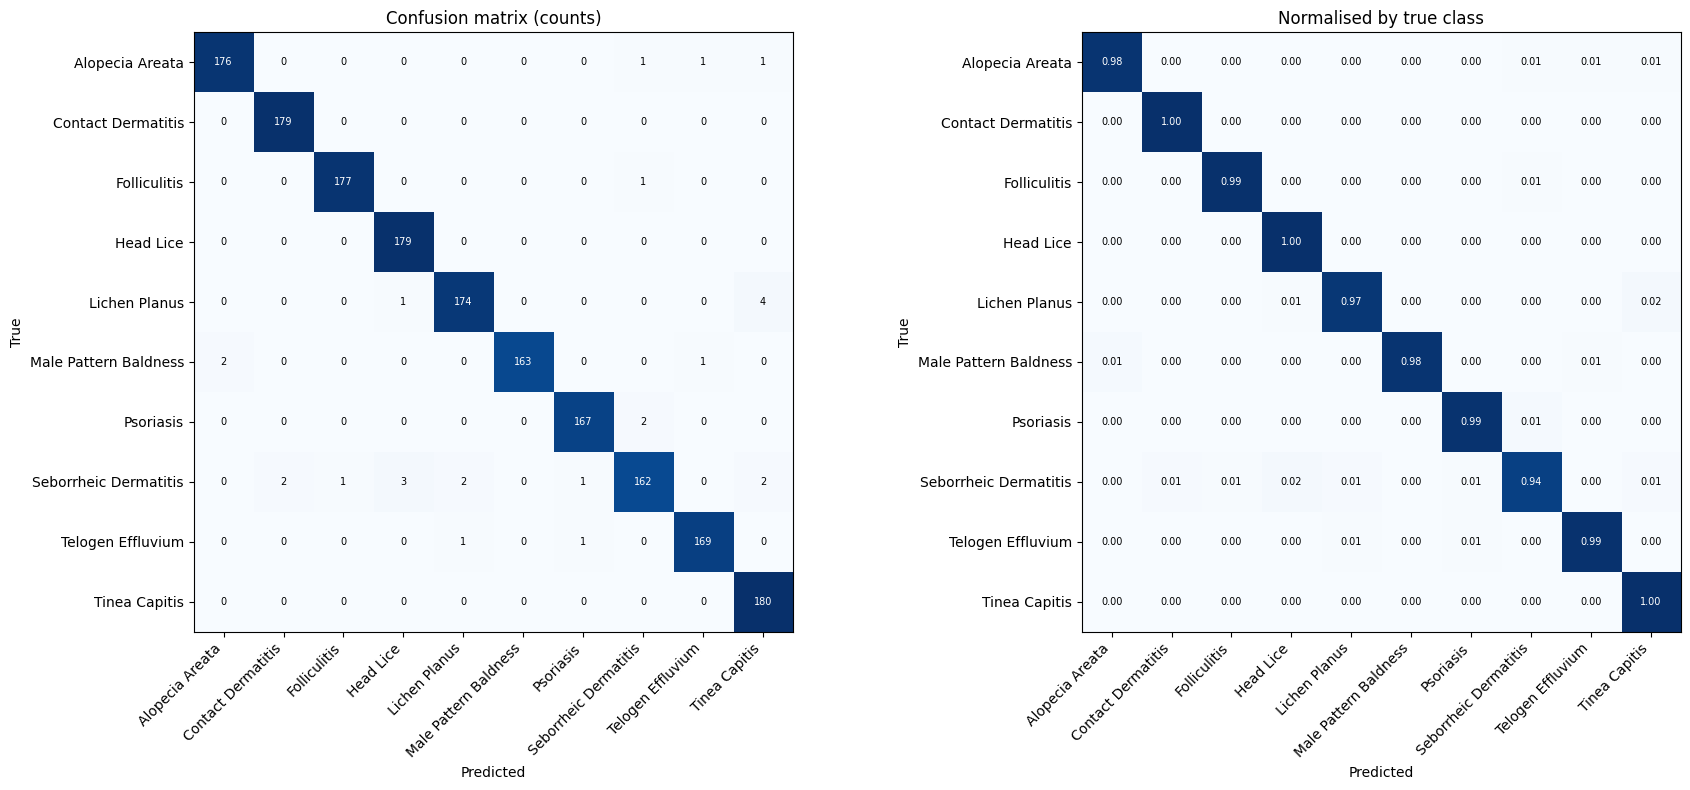

In [29]:
cm = confusion_matrix(y_true, y_pred)
cmn = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(1, 2, figsize=(18, 8))
for a, M, title, fmt in [(ax[0], cm, "Confusion matrix (counts)", "d"), (ax[1], cmn, "Normalised by true class", ".2f")]:
    im = a.imshow(M, cmap="Blues")
    a.set_xticks(range(NUM_CLASSES)); a.set_yticks(range(NUM_CLASSES))
    a.set_xticklabels(class_names, rotation=45, ha="right"); a.set_yticklabels(class_names)
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            a.text(j, i, format(M[i, j], fmt), ha="center", va="center", fontsize=7,
                   color="white" if M[i, j] > M.max() / 2 else "black")
    a.set_xlabel("Predicted"); a.set_ylabel("True"); a.set_title(title)
plt.tight_layout(); plt.savefig(f"{RUN_DIR}/confusion_matrix.png", dpi=150); plt.show()
pd.DataFrame(cm, index=class_names, columns=class_names).to_csv(f"{RUN_DIR}/confusion_matrix.csv")

### Cell 29 - 95% bootstrap confidence intervals
Resamples the test set 1000 times. Report as `accuracy = 0.xx (95% CI lo-hi)`.

In [30]:
rng = np.random.default_rng(SEED)
n = len(y_true)
accs, f1s = [], []
for _ in range(1000):
    idx = rng.integers(0, n, n)
    accs.append((y_true[idx] == y_pred[idx]).mean())
    f1s.append(f1_score(y_true[idx], y_pred[idx], average="macro", zero_division=0))
ci = {"accuracy_ci95": [float(np.percentile(accs, 2.5)), float(np.percentile(accs, 97.5))],
      "macro_f1_ci95": [float(np.percentile(f1s, 2.5)), float(np.percentile(f1s, 97.5))]}
print(f"Accuracy : {acc:.4f}  95% CI [{ci['accuracy_ci95'][0]:.4f}, {ci['accuracy_ci95'][1]:.4f}]")
print(f"Macro-F1 : {f1:.4f}  95% CI [{ci['macro_f1_ci95'][0]:.4f}, {ci['macro_f1_ci95'][1]:.4f}]")
json.dump(ci, open(f"{RUN_DIR}/test_bootstrap_ci.json", "w"), indent=2)

Accuracy : 0.9846  95% CI [0.9789, 0.9903]
Macro-F1 : 0.9845  95% CI [0.9785, 0.9902]


### Cell 30 - Most confused class pairs

In [31]:
off = [(class_names[i], class_names[j], int(cm[i, j])) for i in range(NUM_CLASSES)
       for j in range(NUM_CLASSES) if i != j and cm[i, j] > 0]
conf_df = pd.DataFrame(sorted(off, key=lambda t: -t[2]), columns=["true", "predicted_as", "count"])
print(conf_df.head(10).to_string(index=False))
conf_df.to_csv(f"{RUN_DIR}/confused_pairs.csv", index=False)

                 true          predicted_as  count
        Lichen Planus         Tinea Capitis      4
Seborrheic Dermatitis             Head Lice      3
Male Pattern Baldness       Alopecia Areata      2
            Psoriasis Seborrheic Dermatitis      2
Seborrheic Dermatitis    Contact Dermatitis      2
Seborrheic Dermatitis         Lichen Planus      2
Seborrheic Dermatitis         Tinea Capitis      2
      Alopecia Areata Seborrheic Dermatitis      1
      Alopecia Areata     Telogen Effluvium      1
      Alopecia Areata         Tinea Capitis      1


### Cell 31 - Confident mistakes (error analysis)
The 12 test images the model got wrong with the highest confidence. Check them by eye:
label noise, hard images, or a real model weakness? This is a good discussion point for the thesis.

27 wrong predictions out of 1753


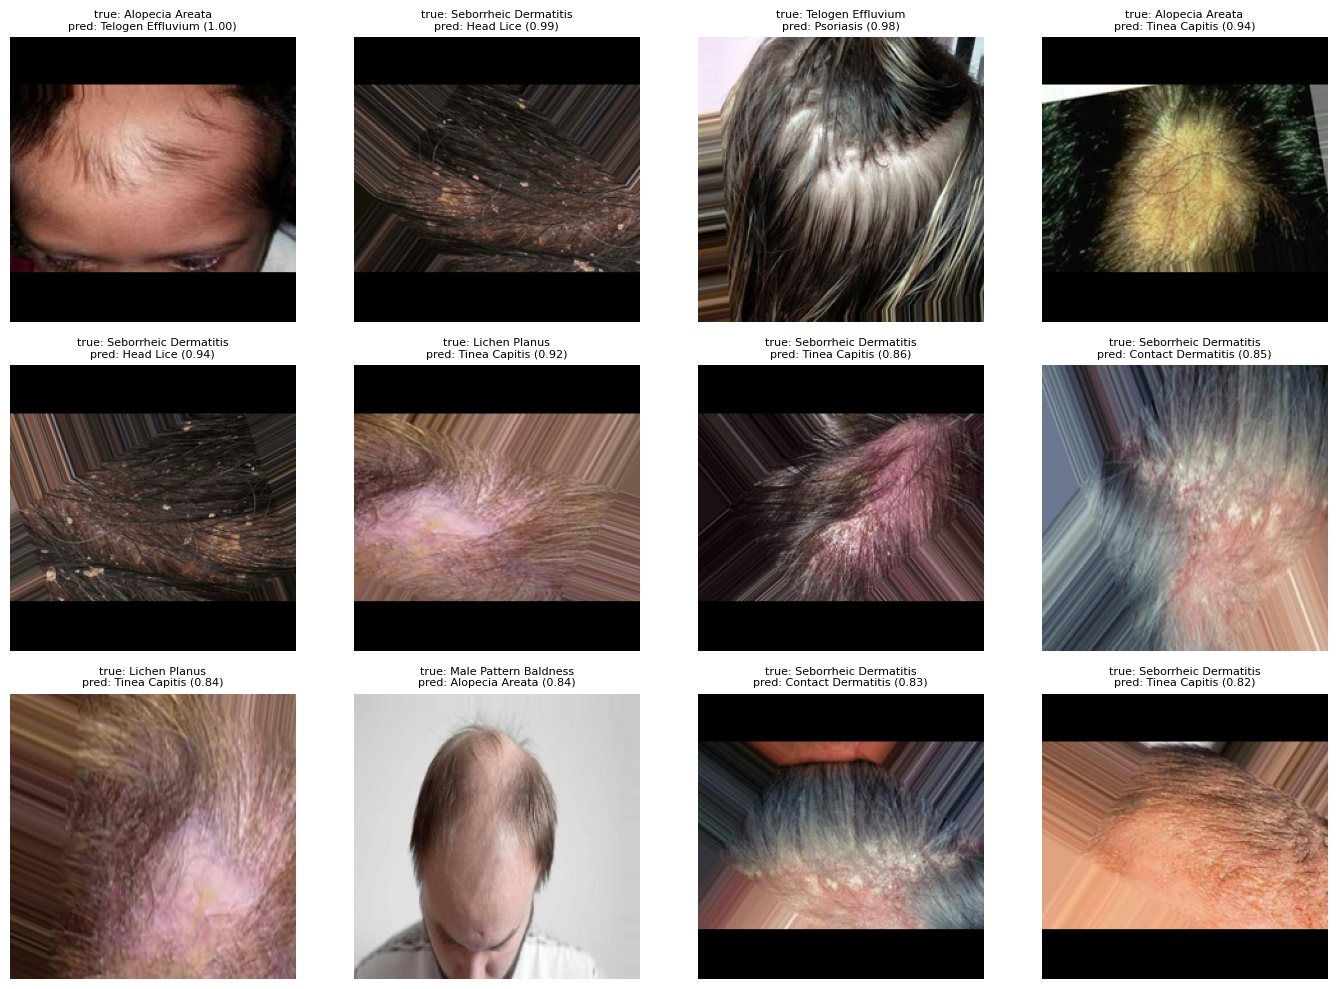

In [32]:
wrong = np.where(y_true != y_pred)[0]
print(f"{len(wrong)} wrong predictions out of {len(y_true)}")
if len(wrong):
    top = wrong[np.argsort(-y_prob.max(axis=1)[wrong])][:12]
    fig, ax = plt.subplots(3, 4, figsize=(14, 10))
    for a, i in zip(ax.ravel(), top):
        a.imshow(Image.open(test_files[i])); a.axis("off")
        a.set_title(f"true: {class_names[y_true[i]]}\npred: {class_names[y_pred[i]]} ({y_prob[i].max():.2f})", fontsize=8)
    for a in ax.ravel()[len(top):]:
        a.axis("off")
    plt.tight_layout(); plt.savefig(f"{RUN_DIR}/confident_errors.png", dpi=130); plt.show()

### Cell 32 - Confidence vs correctness
A well-behaved model is more confident when it is right.

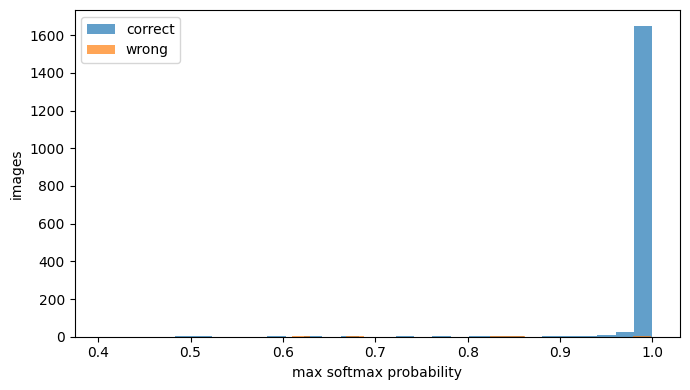

mean confidence  correct: 0.992   wrong: 0.736


In [33]:
conf = y_prob.max(axis=1)
plt.figure(figsize=(7, 4))
plt.hist(conf[y_true == y_pred], bins=30, alpha=0.7, label="correct")
plt.hist(conf[y_true != y_pred], bins=30, alpha=0.7, label="wrong")
plt.xlabel("max softmax probability"); plt.ylabel("images"); plt.legend()
plt.tight_layout(); plt.savefig(f"{RUN_DIR}/confidence_hist.png", dpi=130); plt.show()
print(f"mean confidence  correct: {conf[y_true == y_pred].mean():.3f}   wrong: {conf[y_true != y_pred].mean() if (y_true != y_pred).any() else float('nan'):.3f}")

## F. Save everything

### Cell 33 - Save the final model and an experiment summary

In [34]:
final_model.save(f"{RUN_DIR}/final_model.keras")
summary = {
    "run_name": RUN_NAME,
    "seed": SEED,
    "mixed_precision": MIXED_PRECISION,
    "preprocess": PREPROCESS,
    "fine_tune_from_layer": FINE_TUNE_FROM_LAYER,
    "selected_checkpoint": best_name,
    "n_images": {"train": len(train_files), "val": len(val_files), "test": len(test_files)},
    "val": {k: res[best_name][k] for k in ["val_loss", "val_acc"]},
    "test_metrics": metrics,
    "test_bootstrap_ci": ci,
    "tf_version": tf.__version__,
}
json.dump(summary, open(f"{RUN_DIR}/experiment_summary.json", "w"), indent=2)
print(json.dumps(summary, indent=2))
print("\nAll files saved in:", RUN_DIR)
print(sorted(os.listdir(RUN_DIR)))

{
  "run_name": "densenet169_seed42_20261023_165946",
  "seed": 42,
  "mixed_precision": true,
  "preprocess": "repo_01",
  "fine_tune_from_layer": "conv5_block1_0_bn",
  "selected_checkpoint": "phase2",
  "n_images": {
    "train": 8185,
    "val": 1755,
    "test": 1753
  },
  "val": {
    "val_loss": 0.03656776249408722,
    "val_acc": 0.9874643683433533
  },
  "test_metrics": {
    "accuracy": 0.9845978322875071,
    "balanced_accuracy": 0.9844502954896838,
    "macro_precision": 0.9848229501037424,
    "macro_recall": 0.9844502954896838,
    "macro_f1": 0.9845329106720474,
    "weighted_f1": 0.9845387294448587,
    "cohen_kappa": 0.9828844870119398,
    "macro_auc_ovr": 0.999896924592434
  },
  "test_bootstrap_ci": {
    "accuracy_ci95": [
      0.9788933257273246,
      0.9903023388476897
    ],
    "macro_f1_ci95": [
      0.9784561435339432,
      0.990178716312527
    ]
  },
  "tf_version": "2.21.0"
}

All files saved in: /content/drive/MyDrive/Hair-Disease-Research/results/de